       x      y    c
0  61607  11064 -1.0
1  35042  57166 -1.0
2  12197  60429 -1.0
3  58920  12341 -1.0
4  26979  47662 -1.0
Printing cells...


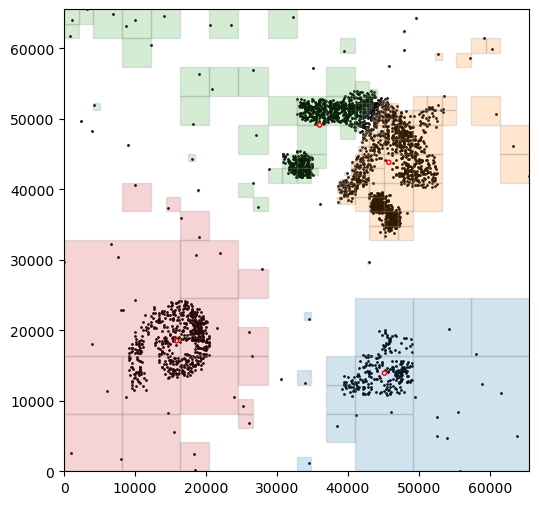

Done.


In [30]:
# -*- coding: utf-8 -*-
"""
Created on Thu Apr 18 17:38:14 2019

@author: plasek
"""

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.patches import Circle

def get_spaced_colors(n):
    max_value = 16581375 #255**3
    interval = int(max_value / n)
    colors = [hex(I)[2:].zfill(6) for I in range(0, max_value, interval)]
    
    return [(int(i[:2], 16), int(i[2:4], 16), int(i[4:], 16)) for i in colors]

colors = get_spaced_colors(10)

cp = r'my-file-2d-N.txt'
#cp = r'C:\Users\piotr\IdeaProjects\clustering\data\random_100000.csv'

dfp = pd.read_csv(cp, names=['x', 'y', 'c'], sep=',')
#dfp = dfp.sample(1000)

# res
cr = r'my-file-2d-normalized_pikMeans_(k=4, mi=5)_iter_4.csv'
#cr = r'C:\Users\piotr\IdeaProjects\clustering\results\random_100000_pikMeans_(k=8, mi=5)_iter_4.csv'

dfr = pd.read_csv(cr)

x, y = dfp['x'], dfp['y']

print(dfp.head())

fig, ax = plt.subplots()

fig.set_figheight(6)
fig.set_figwidth(6)

ax.set_xlim(0, pow(2,16)-1)
ax.set_ylim(0, pow(2,16)-1)
#ax.scatter(figsize=(12,12))

ax.scatter(x, y, facecolor='black', s=1, alpha=1)

print('Printing cells...')

for i, r in dfr.iterrows():
    cid = int(r['id'])
    
    if cid != -2:
        c = 'C{}'.format(cid)
        #print(c)
        rect = Rectangle((r['x'], r['y']), r['s'], r['s'], edgecolor='gray',
                         facecolor=c, alpha = .2)
        ax.add_patch(rect)
    else:
        c = 'C{}'.format(cid)
        rect = Circle((r['x'], r['y']), 300, edgecolor='red', facecolor='None', alpha = 1)
        ax.add_patch(rect)

plt.show()

print('Done.')